# Hartland Quay (Devon) — composed figure

The paper figure, composed from renders that `05e_hartland_quay_figures` has already made:

- the top panel, the data: the photogrammetric point cloud with the fitted traces and the
  bedding (`renders/data/render.png`, from 05e's data section);
- the main panel, the LDI cut view (`renders/ldi_terraces/render.png`);
- an inset at the top right of it, the same view of the Surfe fit (`renders/surfe_terraces/`).

Run 05e with `METHOD = "ldi"` and `MEMBER` set to the member you want here (and its data section) and with `METHOD = "surfe"` first; each
saves its render and camera (`camera.json`). All three must share the camera (same box and
view), which is checked.
Nothing is rendered, fitted or meshed here; `curlew`, `torch` and `surfepy` are not needed, and
only `figures/` is written.

## Setup

In [3]:
import json
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from PIL import Image

import sys
sys.path.insert(0, str(Path("..").resolve()))  # publication/: figstyle, exploded3d
import figstyle
import exploded3d
figstyle.apply()

FIG_DIR = Path("figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
MEMBER = 19                         # LDI ensemble member rendered by 05e (19 is the member in the paper)
LDI_TAG = "ldi" if MEMBER == 0 else f"ldi_member_{MEMBER:02d}"     # as 05e names it
RENDERS = {"ldi": Path("renders") / f"{LDI_TAG}_terraces", "surfe": Path("renders") / "surfe_terraces"}
RENDERS["data"] = Path("renders") / "data"

views = {key: json.loads((d / "camera.json").read_text()) for key, d in RENDERS.items()}
renders = {key: np.asarray(Image.open(d / "render.png").convert("RGBA")) for key, d in RENDERS.items()}
cam, RESOLUTION = views["ldi"]["cam"], tuple(views["ldi"]["resolution"])
same = all(all(np.allclose(np.asarray(views[o]["cam"][k], dtype=float), np.asarray(v, dtype=float))
               for k, v in cam.items() if not isinstance(v, str)) and views[o]["resolution"] == list(RESOLUTION)
           for o in ("surfe", "data"))
assert same, "the renders were made with different cameras: re-run 05e for LDI, Surfe and the data"

print({key: views[key]["n_extrema"] for key in ("ldi", "surfe")}, "interior extrema")


{'ldi': 0, 'surfe': 9} interior extrema


## Compose

The LDI view is the main panel, `MAIN_W` of the width, its bottom-right corner fixed by
`MAIN_RIGHT` and `MAIN_BOTTOM`. The data and Surfe views share one smaller scale (`INSET_W` sets
the Surfe width; the data panel follows from the same inches per render pixel) and sit above it,
offset from each other: Surfe right-aligned, data left-aligned, each slid up only until its render
clears the LDI render (`INSET_GAP`) and the data clears Surfe by `PANEL_GAP`. They are drawn over the
main panel (the renders are transparent). One set of model axes, at the data and Surfe scale, sits
at the top between the data and Surfe panels; the LDI title gives its enlargement. The colour key sits below Surfe, between b and c, and the trace and bedding key inside the data panel, in its empty bottom-left corner;
the colour key is part of Surfe's footprint while it slides. Surfe's title carries the interior-extremum mark, as in the
Claudius figure. The panels are lettered a (data), b (Surfe) and c (LDI), each letter
just left of its title.

data and Surfe at 0.52 of the LDI scale; figure 137 mm tall


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array


wrote
  figures/fig05_hartland_quay_member_19.pdf
  figures/fig05_hartland_quay_member_19.png


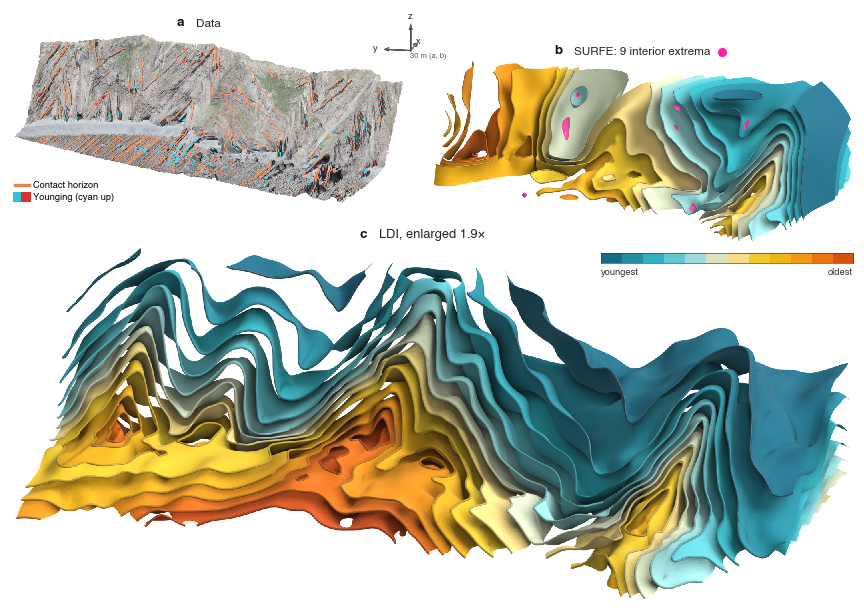

In [4]:
MAIN_W = 1.00                      # main panel width, as a fraction of the width inside the margins
FRAME_H = 1.0                      # frame height, as a multiple of the main render's height at full width
MAIN_RIGHT = 0.00                  # gap right of the main panel, as a fraction of the width inside the margins
MAIN_BOTTOM = 0.08                 # gap below it, as a fraction of the full-width render's height
                                   # (the bottom-right corner stays put; MAIN_W grows the panel up and left)
INSET_W = 0.50                     # Surfe width, as a fraction of the width inside the margins (sets the data scale too)
INSET_GAP = 0.04                   # in, least clearance between the inset's and the main panel's renders
                                   # (the inset sits right-aligned, as low as it can go and stay clear;
                                   #  a larger INSET_W grows it up and left, and the figure taller)
PANEL_GAP = 0.22                   # in, least clearance between the data and Surfe renders (room for a title)
KEY_W, KEY_H = 0.30, 0.09          # colour key: width (fraction of the width inside the margins) and bar height, in
TITLE_SIZE = 10.0
DPI = 300


def cropped(img, pad=10):
    a = img[..., 3]
    rows, cols = np.flatnonzero(a.max(1) > 8), np.flatnonzero(a.max(0) > 8)
    r0, r1 = max(rows[0] - pad, 0), min(rows[-1] + pad + 1, a.shape[0])
    c0, c1 = max(cols[0] - pad, 0), min(cols[-1] + pad + 1, a.shape[1])
    return img[r0:r1, c0:c1], (r0, c0)


def panel_pixels(arr, w_in, h_in):
    # Resample to the panel's size at DPI ourselves, on premultiplied alpha (no halo at the edges).
    size = (max(1, round(w_in * DPI)), max(1, round(h_in * DPI)))
    return np.asarray(Image.fromarray(arr).convert("RGBa").resize(size, Image.Resampling.LANCZOS).convert("RGBA"))


main, _ = cropped(renders["ldi"])
inset_img, _ = cropped(renders["surfe"])
data_img, _ = cropped(renders["data"])
W = figstyle.PRINT_WIDTH
left, right, top, bottom = 0.04, 0.04, 0.30, 0.10
avail = W - left - right                                   # the insets, axes and key use the full width
w_main = MAIN_W * avail
x_main = left + (1.0 - MAIN_RIGHT) * avail - w_main          # its bottom-right corner pinned
h_main = w_main * main.shape[0] / main.shape[1]
h_box = FRAME_H * avail * main.shape[0] / main.shape[1]    # a frame taller than the main panel
y_main = bottom + MAIN_BOTTOM * avail * main.shape[0] / main.shape[1]
def masks_overlap(img_a, box_a, img_b, box_b, gap, res=60):
    """Do two renders, placed at boxes (x, y, w, h) in inches, have drawn pixels within `gap` in of each other?"""
    from scipy.ndimage import binary_dilation
    x0, y0 = min(box_a[0], box_b[0]), min(box_a[1], box_b[1])
    x1 = max(box_a[0] + box_a[2], box_b[0] + box_b[2]); y1 = max(box_a[1] + box_a[3], box_b[1] + box_b[3])
    canvas = [np.zeros((int(np.ceil((y1 - y0) * res)) + 2, int(np.ceil((x1 - x0) * res)) + 2), bool) for _ in range(2)]
    for c, img, (x, y, w, h) in zip(canvas, (img_a, img_b), (box_a, box_b)):
        size = (max(1, round(w * res)), max(1, round(h * res)))
        m = np.asarray(Image.fromarray(img[..., 3]).resize(size, Image.Resampling.BILINEAR)) > 8
        r, col = int(round((y1 - (y + h)) * res)), int(round((x - x0) * res))      # rows run down from the top
        c[r:r + m.shape[0], col:col + m.shape[1]] |= m
    grown = binary_dilation(canvas[0], iterations=max(1, int(round(gap * res))))
    return bool((grown & canvas[1]).any())



# data and Surfe at one scale (the same camera and resolution, so the same inches per render pixel),
# and the LDI panel enlarged by `factor` against them
w_in = INSET_W * avail
in_per_px = w_in / inset_img.shape[1]
h_in = inset_img.shape[0] * in_per_px
w_d, h_d = data_img.shape[1] * in_per_px, data_img.shape[0] * in_per_px
factor = (w_main / main.shape[1]) / in_per_px

# Surfe: right-aligned, slid up from the bottom until its render clears the LDI render and title
solid = np.full((8, 8, 4), 255, np.uint8)                       # a stand-in for the LDI title's box
title_box = (x_main + 0.5 * w_main - 1.3, y_main + h_main, 2.6, 0.32)
x_in, y_in = left + avail - w_in, y_main
key_w = KEY_W * avail
key_box = lambda y: (x_in + w_in - key_w, y - 0.08 - KEY_H - 0.17, key_w, KEY_H + 0.17)   # bar and its labels, below Surfe
while (masks_overlap(main, (x_main, y_main, w_main, h_main), inset_img, (x_in, y_in, w_in, h_in), INSET_GAP)
       or masks_overlap(solid, title_box, inset_img, (x_in, y_in, w_in, h_in), INSET_GAP)
       or masks_overlap(main, (x_main, y_main, w_main, h_main), solid, key_box(y_in), INSET_GAP)
       or masks_overlap(solid, title_box, solid, key_box(y_in), INSET_GAP)):
    y_in += 0.02
# data: left-aligned, slid up until it clears the LDI render, the LDI title and, by PANEL_GAP, the Surfe render
# (its key sits inside its own box, in the empty bottom-left corner, so it takes no room of its own)
x_d, y_d = left, y_main
while (masks_overlap(main, (x_main, y_main, w_main, h_main), data_img, (x_d, y_d, w_d, h_d), INSET_GAP)
       or masks_overlap(solid, title_box, data_img, (x_d, y_d, w_d, h_d), INSET_GAP)
       or masks_overlap(inset_img, (x_in, y_in, w_in, h_in), data_img, (x_d, y_d, w_d, h_d), PANEL_GAP)):
    y_d += 0.02
H = max(top + h_box + bottom, y_in + h_in + top, y_d + h_d + top)
print(f"data and Surfe at {1 / factor:.2f} of the LDI scale; figure {25.4 * H:.0f} mm tall")
fig = figstyle.print_figure(height=H)

ax = fig.add_axes((x_main / W, y_main / H, w_main / W, h_main / H))
ax.imshow(panel_pixels(main, w_main, h_main), interpolation="none")
ax.set_axis_off()
titled = [(ax.set_title(f"LDI, enlarged {factor:.1f}\u00d7", color="0.15", fontproperties=figstyle._fp(size=11)), "c")]


def inset(img, box, title, letter):
    x, y, w, h = box
    pic = fig.add_axes((x / W, y / H, w / W, h / H), zorder=5)       # transparent: the main render shows through
    pic.imshow(panel_pixels(img, w, h), interpolation="none")
    pic.set_axis_off()
    pic.patch.set_alpha(0.0)
    t = pic.set_title(title, color="0.15", fontproperties=figstyle._fp(size=TITLE_SIZE), pad=3)
    titled.append((t, letter))

n_surfe = views["surfe"]["n_extrema"]
inset(data_img, (x_d, y_d, w_d, h_d), "Data", "a")
inset(inset_img, (x_in, y_in, w_in, h_in), f"SURFE: {n_surfe} interior extrema", "b")

# one set of model axes, at the scale of the data and Surfe panels (the LDI title gives its enlargement),
# at the top, between the data and Surfe panels
g = np.asarray(Image.open(RENDERS["ldi"] / "axes.png").convert("RGBA"))
g_rows, g_cols = np.flatnonzero(g[..., 3].max(1) > 8), np.flatnonzero(g[..., 3].max(0) > 8)
gpad = 45
gr0, gr1 = g_rows[0] - gpad, g_rows[-1] + gpad + 1
gc0, gc1 = g_cols[0] - gpad, g_cols[-1] + gpad + 1
gw, gh = (gc1 - gc0) * in_per_px, (gr1 - gr0) * in_per_px
GNOMON_GAP = 0.30                                             # in, clear of the data panel's cloud
gx = min(x_d + w_d + GNOMON_GAP, x_in - gw - 0.05)
gax = fig.add_axes((gx / W, (H - top - gh + 0.15) / H, gw / W, gh / H), zorder=6)
gax.imshow(panel_pixels(g[gr0:gr1, gc0:gc1], gw, gh), interpolation="none", extent=(gc0, gc1, gr1, gr0))
v = views["ldi"]
pix = exploded3d.project(np.vstack([v["gnomon_origin"], *v["gnomon_tips"].values()]), cam, RESOLUTION)
for label, tip in zip(v["gnomon_tips"], pix[1:]):
    at = tip + 0.25 * (tip - pix[0])
    gax.text(at[0], at[1], label, ha="center", va="center", fontproperties=figstyle._fp(size=8), color="0.2")
gax.text(pix[0][0], gr1 - 4, f"{v['gnomon_length']:.0f} m (a, b)", ha="left", va="bottom",
         fontproperties=figstyle._fp(size=6.5), color="0.35")
gax.set_xlim(gc0, gc1); gax.set_ylim(gr1, gr0); gax.set_axis_off()

# colour key (youngest to oldest) below Surfe, right-aligned, between b and c
kx, ky, kw, kh = key_box(y_in)
key = fig.add_axes((kx / W, (ky + 0.17) / H, kw / W, KEY_H / H), zorder=6)
key.imshow(np.array([matplotlib.colors.to_rgb(c) for c in v["colors"]])[None], aspect="auto")
key.set_xticks([]); key.set_yticks([])
for side in key.spines.values():
    side.set_linewidth(0.4)
key.text(0.0, -0.4, "youngest", transform=key.transAxes, ha="left", va="top", fontproperties=figstyle._fp(size=8), color="0.2")
key.text(1.0, -0.4, "oldest", transform=key.transAxes, ha="right", va="top", fontproperties=figstyle._fp(size=8), color="0.2")

# the trace and bedding key inside the data panel, in its empty bottom-left corner (below the beach)
bed_up, bed_down = views["data"]["bedding_colors"]
from matplotlib.legend_handler import HandlerTuple
fig.legend([Line2D([], [], color=views["data"]["trace_color"], lw=2.0),
            (Line2D([], [], ls="", marker="s", ms=6, mfc=bed_up, mec="none"),
             Line2D([], [], ls="", marker="s", ms=6, mfc=bed_down, mec="none"))],
           ["Contact horizon", "Younging (cyan up)"], loc="lower left", ncol=1, frameon=False,
           handler_map={tuple: HandlerTuple(ndivide=None, pad=0.2)}, prop=figstyle._fp(size=8),
           bbox_to_anchor=(x_d / W, y_d / H), borderaxespad=0.0, handletextpad=0.4, labelspacing=0.3)

# each panel's letter just left of its title
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
for t, letter in titled:
    bb = t.get_window_extent(renderer).transformed(fig.transFigure.inverted())
    fig.text(bb.x0 - 0.10 / W, bb.y0, letter, ha="right", va="bottom", color="0.08", zorder=7,
             fontproperties=figstyle._fp(bold=True, size=8.0 / figstyle.TEXT_SCALE))
    if letter == "b" and n_surfe:                # Surfe: the extremum mark after its title, as in the Claudius figure
        fig.add_artist(Line2D([bb.x1 + 0.09 / W], [0.5 * (bb.y0 + bb.y1)], transform=fig.transFigure, ls="",
                              marker="o", ms=6, mfc="#FF1FA8", mec="white", mew=0.5, zorder=7))

written = figstyle.save(fig, FIG_DIR / ("fig05_hartland_quay" if MEMBER == 0 else f"fig05_hartland_quay_member_{MEMBER:02d}"))
print("wrote", *written, sep="\n  ")
plt.show()